In [1]:
from sherpa.astro import ui
from astropy.io import fits
from astropy.table import Table

In [2]:
from sherpa.astro.io import read_pha, read_arf, read_rmf

In [3]:
TG_PART = {1: 'HEG', 2: 'MEG', 3: 'LEG'}

tgcat_id = 2459
tgcat_id = 6972

phalist = read_pha(f"/Users/guenther/data/tg_test_data/arcA/pha2/tgcid_{tgcat_id}_pha2.gz")
phas = {}
for pha in phalist:
    tg_m = int(pha.header['TG_M'])
    tg_part = int(pha.header['TG_PART'])
    if abs(tg_m) > 1:
        continue
    arf = read_arf(f"/Users/guenther/data/tg_test_data/arcA/arf/tgcid_{tgcat_id}_{TG_PART[tg_part]}_{tg_m}.arf.gz")
    #rmf = read_rmf(
    #    f"/Users/guenther/data/tg_test_data/arcA/rmf/tgcid_{tgcat_id}_{TG_PART[tg_part]}_{tg_m}.rmf.gz"
    #)
    pha.set_response(arf, None)
    phas[TG_PART[tg_part], int(tg_m)] = pha

statistical errors were found in file '/Users/guenther/data/tg_test_data/arcA/pha2/tgcid_6972_pha2.gz'
but not used; to use them, re-read with use_errors=True
read background_up into a dataset from file /Users/guenther/data/tg_test_data/arcA/pha2/tgcid_6972_pha2.gz
read background_down into a dataset from file /Users/guenther/data/tg_test_data/arcA/pha2/tgcid_6972_pha2.gz


In [4]:
from sherpa.astro.plot import DataPHAPlot
from sherpa.stats import Chi2, Chi2Gehrels, Cash, CStat, LeastSq, Likelihood, Poisson, WStat

ImportError: cannot import name 'Poisson' from 'sherpa.stats' (/Users/guenther/miniforge3/envs/ciao-4.18/lib/python3.12/site-packages/sherpa/stats/__init__.py)

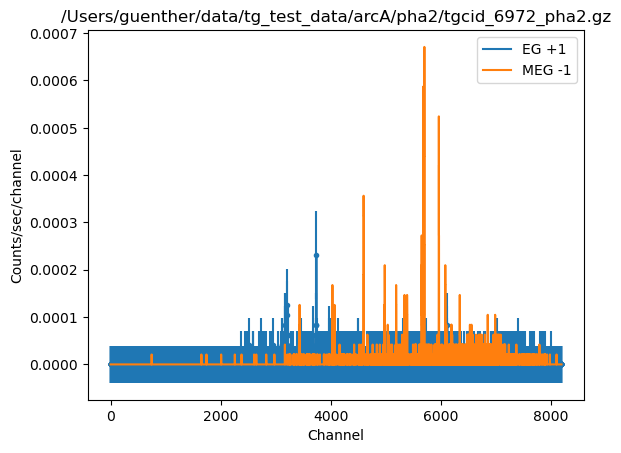

In [5]:
dataplot = DataPHAPlot()
dataplot.prepare(phas[('HEG', 1)], stat=Chi2Gehrels())
dataplot.plot(label="EG +1", linestyle='-', yerrorbars=True)
dataplot.prepare(phas[("MEG", -1)])
dataplot.plot(overplot=True, label="MEG -1", linestyle='-', marker=None)

In [7]:
hm1 = phas[("HEG", -1)]
hp1 = phas[("HEG", 1)]
mm1 = phas[("MEG", -1)]
mp1 = phas[("MEG", 1)]

In [28]:
hm1.exposure, hp1.exposure

(np.float64(47696.490944906), np.float64(47696.490944906))

In [8]:
am1 = hm1.get_arf(1)
ap1 = hp1.get_arf(1)


In [13]:
import copy
from sherpa.astro.data import DataPHA

def coadd(phas: list[DataPHA]) -> DataPHA:
    """Coadd multiple DataPHA objects into a single DataPHA object.

    Parameters
    ----------
    phas : list[DataPHA]
        List of DataPHA objects to coadd.

    Returns
    -------
    DataPHA
        Coadded DataPHA object.
    """
    if not phas:
        raise ValueError("No DataPHA objects provided for coaddition.")

    # Ensure all DataPHA objects have the same exposure time
    exposure = phas[0].exposure
    if not all(pha.exposure == exposure for pha in phas):
        raise ValueError("All DataPHA objects must have the same exposure time.")

    # Create a new DataPHA object for the coadded result
    coadded_pha = copy.deepcopy(phas[0])
    
    # Sum counts and combine ARFs
    coadded_pha.counts = sum(pha.counts for pha in phas)
    
    # Combine ARFs (assuming they are compatible)
    combined_arf = copy.deepcopy(phas[0].get_arf(1))
    for pha in phas[1:]:
        arf = pha.get_arf(1)
        combined_arf.dep += arf.dep  # Combine the effective area

    coadded_pha.set_response(combined_arf, None)

    return coadded_pha 

In [21]:
coadded_pha = coadd([hm1,hp1, mm1, mp1])
coadded_pha.group_counts(5)
coadded_pha.set_analysis("wave")

Text(0, 0.5, 'Counts/sec/Angstrom')

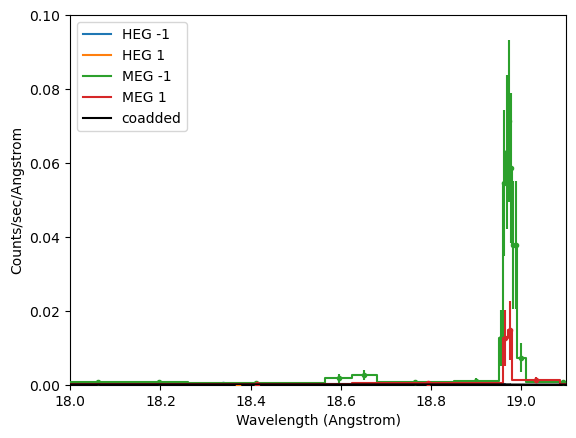

In [22]:
dataplot = DataPHAPlot()

for k, v in phas.items():
    v.group_counts(5)
    v.set_analysis("wave")
    dataplot.prepare(v, stat=Chi2Gehrels())
    dataplot.plot(label=f"{k[0]} {k[1]}", linestyle="-", yerrorbars=True, overplot=True)

dataplot.prepare(coadded_pha, stat=Chi2Gehrels())
dataplot.plot(overplot=True, label="coadded", linestyle="-", marker=None, color="k")

import matplotlib.pyplot as plt

ax = plt.gca()
ax.set_xlim(18, 19.1)
ax.set_ylim(0, 0.1)
ax.set_xlabel(dataplot.xlabel)
ax.set_ylabel(dataplot.ylabel)


In [19]:
dataplot.xlabel

'Wavelength (Angstrom)'